#02_PREPROCESAMIENTO: partición y tratamiento de datos:

In [94]:
!git clone -b PREPROCESAMIENTO https://github.com/gabriela708/Maternal-Health-Risk---Ordinal-Regresion.git
%cd Maternal-Health-Risk---Ordinal-Regresion

Cloning into 'Maternal-Health-Risk---Ordinal-Regresion'...
remote: Enumerating objects: 67, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 67 (delta 9), reused 52 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (67/67), 1.45 MiB | 6.14 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion


In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB
           Age  SystolicBP  DiastolicBP       BS  BodyTemp  HeartRate
count  1014.00      1014.0      1014.00  1014.00   1014.00    1014.00
mean     29.87       113.2        76.46     8.73     98.67      74.30
std      13.47        18.4        13.89     3.29      1.37       8.09
min      10.00        70.0        49.00     6.00     98.00       7.00
25%      19.00       100.0        65.00     6.90     98.00      70.00
50%      26.00       120.0       

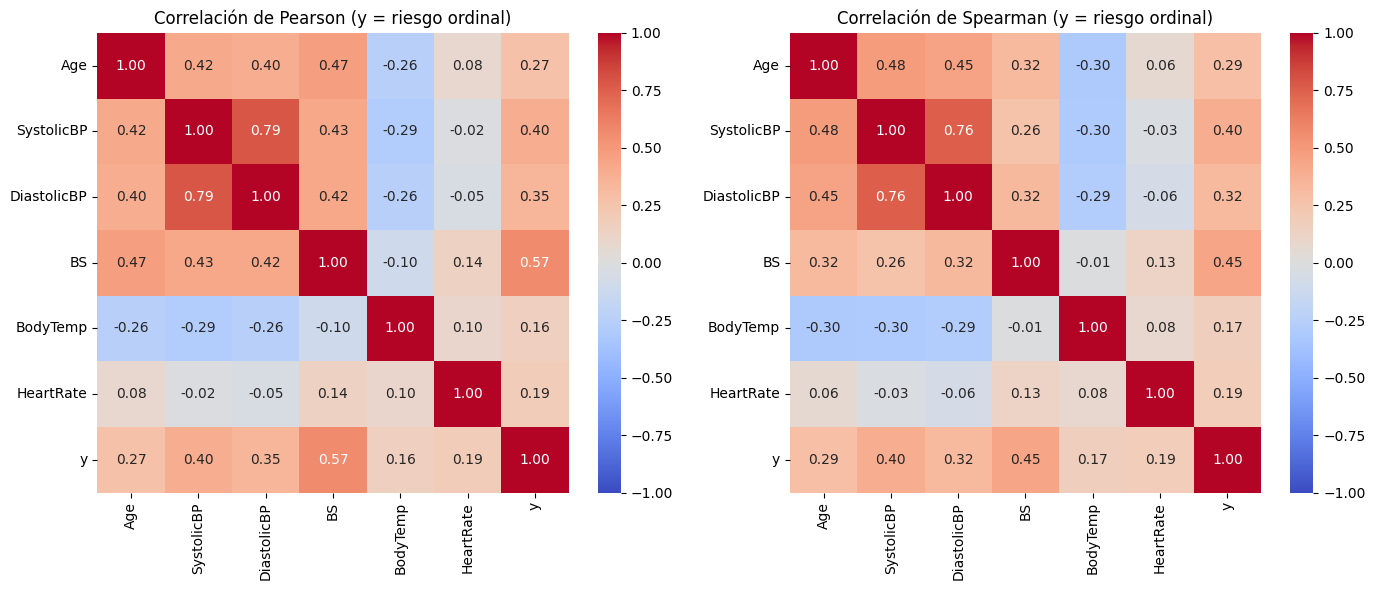

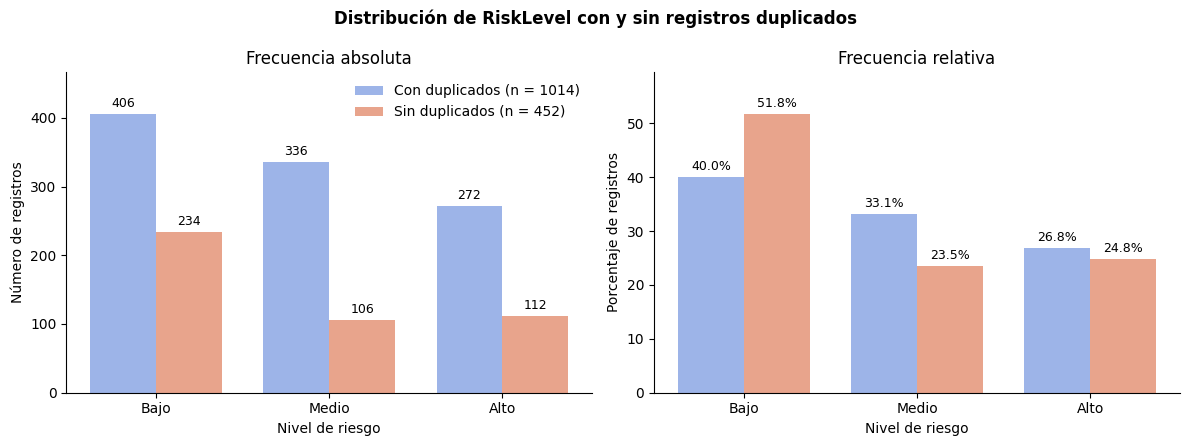

/content/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/src/01_eda.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='RiskLevel', y=var, data=df_u, order=ORDEN,
/content/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/src/01_eda.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='RiskLevel', y=var, data=df_u, order=ORDEN,
/content/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/src/01_eda.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is

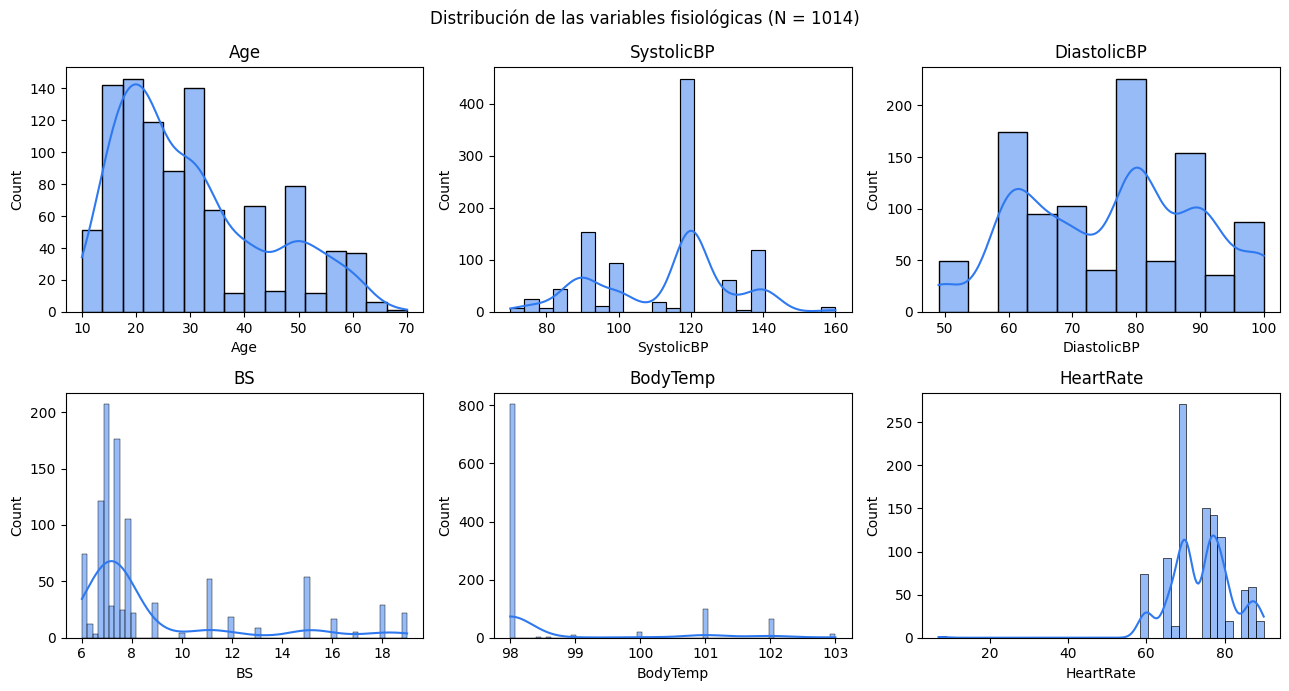

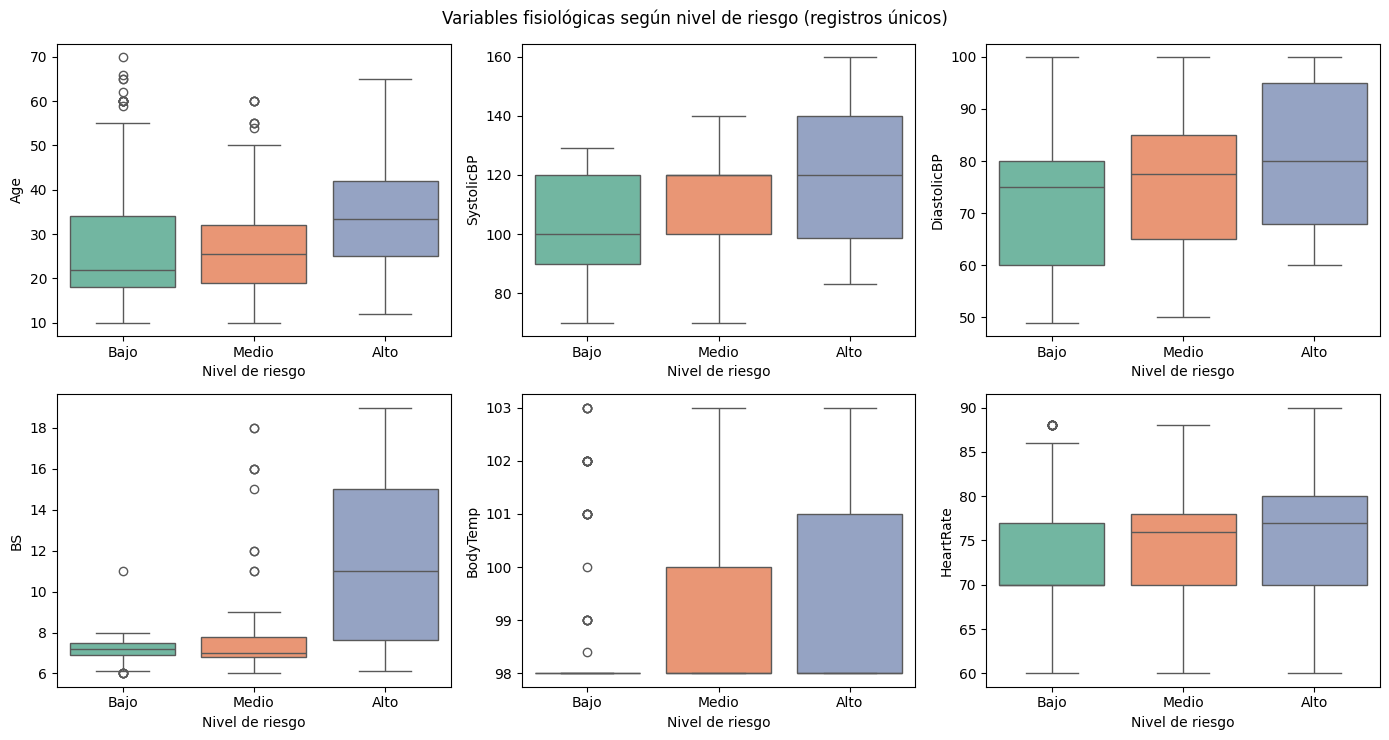

In [96]:
import sys
sys.path.insert(0, "src")
from config import DATA_RAW, DATA_PROCESSED, SEED , LEVELS , ORDEN , L_NOMBRES , PREDICTORS, TARGET
%run src/01_eda.py

In [97]:
df = pd.read_csv(DATA_RAW) #DATA SET A USAR

## TRATAMIENTO DE DUPLICADOS:

In [98]:
df_u=df.drop_duplicates()
df_u.shape , df_u.duplicated().value_counts()

((452, 7),
 False    452
 Name: count, dtype: int64)

Se tomo la decision de elimianar, luego de haber echo el EDA al observar que la gran mayoria de los datos existentes eran duplicados, ya sea tal cual todo un registro o solo ciertos datos los cuales pues con razones logicas poseen pocos valores unicos, inicialmente se pensaba justificar el uso de estos duplicados al (asumiendo) ser registros o varias consultas de una sola paciente, usando más adelante un gruop_Kfold para solucionar un problema de fuga, asi como darle un peso igual a estos duplicados.
Aunque funcional esta solucion, viene sin fundamentos, debido a que la fuente de nuestros datos y nuestros datos no poseen un tipo de seguimiento que nos pueda indicar que son registros de una sola paciente y no de distintos por lo que solo estariamos asumiendo supuestos, ademas existen mucho registros los cuales estan demasiadas veces repetidos, por lo que lo ideal y decision final es eilimarlos completamente, quedandonos con 452 datos unicos sin ninguno repetido

## CODIFICACION DE LA VARIABLE TARGET (ORDINAL)

In [99]:
df_u['RiskLevel'].unique(), LEVELS
df_u.loc[:, "RiskLevel"] = df_u["RiskLevel"].apply(lambda x: str(x))
df.loc[:, "RiskLevel"] = df_u["RiskLevel"].apply(lambda x: str(x))
df_u["RiskLevel"].unique()

array(['high risk', 'low risk', 'mid risk'], dtype=object)

In [100]:
df_u.loc[:,'RiskLevel_cd']=df_u["RiskLevel"].map(LEVELS)
df.loc[:,'RiskLevel_cd']=df_u["RiskLevel"].map(LEVELS)


/tmp/ipykernel_1731/875401401.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_u.loc[:,'RiskLevel_cd']=df_u["RiskLevel"].map(LEVELS)


In [101]:
df_u['RiskLevel_cd'].unique()
df_u.groupby('RiskLevel_cd')['RiskLevel'].value_counts()

,,count
RiskLevel_cd,RiskLevel,
0,low risk,234
1,mid risk,106
2,high risk,112


Se realizo la codificacion de las clases, por el codigo decidido y el orden propuesto, donde "low risk"=0, "mid risk"=1, "high risk"=2, manteniendo la estructura de orden logica 0 < 1 < 2 propuesta inicialmente.

## DATOS POCO PROBABLES O FALLLAS DE DIGITACION

In [102]:
df['HeartRate'].unique()

array([86, 70, 80, 76, 78, 77, 88, 90, 66, 82, 60, 75, 67, 65, 68,  7])

In [103]:
registro_anomalo = df[df['HeartRate'] == 7]
display(registro_anomalo)
df=df[df['HeartRate']!=7]

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel,RiskLevel_cd
499,16,120,75,7.9,98.0,7,low risk,0.0
908,16,120,75,7.9,98.0,7,NaN,NaN


In [104]:
df['HeartRate'].unique()

array([86, 70, 80, 76, 78, 77, 88, 90, 66, 82, 60, 75, 67, 65, 68])

Como visto anteriormente en el analisis de la base de datos, tanto en los datos con duplicados existen registros en los cuales hay valores muy pequeños como en la edad con registros de 13 años hacia abajo, o incluso de los 60 en adelante, lo cual es poco comun pero teniendo en cuenta la poblacion y situacion que trabajamos son pertinentes dejarlas y nos puede indicar algun tipo de comportamoiento, adicionalmente no podemos eliminarlas o indicar algun tipo de razon, debido a falta de criterio medica de nuestra parte
Pero por otro lado (tan solo en el data set con duplicados) aparecen registros duplciados, en los cuales la frecuencia cardiaca es exactamente 7 lo cual no tiene sentido logico al set una frecuencia claramente peligrosa que incluso estaria mostrando que la paciente no esta viva, esto debido a un error de registro o similar, se decide eliminar ya que no afecta a gran escala nuestro flujo de trabajo y solo se presenta en nuestro conjunto de comparacion que es con los datos duplicados

## TRATAMIENTO DE FALTANTES:
Debido a que nuestro data set no presenta ningun dato faltante, tanto en los datos con duplciados y sin, no es necesario hacer ningun proceso de tratamiento de faltantes y es posible seguir con el proceso del split

## PARTICION/SPLIT: train y test

debido a que no existe algun tipo de desbalance de clase, se tomo la deicsion de dividir nuestro data set en dos, con una particion de 75% y 25% para train y test respectivamente, teniendo en cuenta principalmente con datos unicos y su etiqueta y luego (por comparacion) con los datos duplicados pero para cada conjunto (con duplicados y sin) se hace un cruce entre los data set para evitar que exista una fuga de informacion debido a que aunque existe registros duplciados por completo, en el sin duplicados, existen valores que logran repetirse pero no necesameinte son un mismo perfil, por lo mismo es necesario hacer este cruce

In [105]:
df_u = df_u.drop(columns=['RiskLevel'])
df = df.drop(columns=['RiskLevel'])

##SE ELIMINA DEBIDO A QUE YA SE CREO LA QUE ES CON MAPEO

In [110]:
# Perfiles únicos (solo signos) y una etiqueta por perfil para estratificar
perfiles = df_u.groupby(PREDICTORS, as_index=False)['RiskLevel_cd'].max()

perfiles_train, perfiles_test = train_test_split(
    perfiles,
    test_size=0.25,
    random_state=SEED,
    stratify=perfiles['RiskLevel_cd']        # mantiene la proporción de clases
)
perfiles_train = perfiles_train[PREDICTORS]
perfiles_test  = perfiles_test[PREDICTORS]

# Base principal (sin duplicados)
df_train = df_u.merge(perfiles_train, on=PREDICTORS, how='inner')
df_test  = df_u.merge(perfiles_test,  on=PREDICTORS, how='inner')

In [111]:
# Verificación de resultados
print(f"Total de filas originales: {len(df_u)}")
print(f"Filas en Train: {len(df_train)}")
print(f"Filas en Test: {len(df_test)}")
print(f"Suma de filas: {len(df_train) + len(df_test)}")

Total de filas originales: 452
Filas en Train: 335
Filas en Test: 117
Suma de filas: 452


In [114]:
# Base completa (con duplicados), mismos perfiles de train y test
df_train_full = df.merge(perfiles_train, on=PREDICTORS, how='inner')
df_test_full  = df.merge(perfiles_test,  on=PREDICTORS, how='inner')

print(len(perfiles_train.merge(perfiles_test, on=PREDICTORS))) ##Si esto = 0 indica que ningun registro quedo en los dos lados generando fuga de informacion.

0


## ESCALAMIENTO Y ESTADARIAZCION:
Se propone hacer un estadar escaler o Z-score con la media y la desviacion estandar pero solo en el data set de entrenamiento para evitar esta fuga de informacion y luego aplicando estos valores al grupo de test, para luego guardar esta informacion de la media y desviacion, para más adelante poder hacer el cambio a las medidas originales.

In [116]:
scaler = StandardScaler()
# 2. FIT_TRANSFORM en Train: Calcula la media y desviación estándar SOLO con train y las aplica
X_train_scaled = scaler.fit_transform(df_train[PREDICTORS])

# 3. TRANSFORM en Test: Aplica EXACTAMENTE las mismas medias y desviaciones de train al test
X_test_scaled = scaler.transform(df_test[PREDICTORS])

df_parametros = pd.DataFrame({
    'Variable': PREDICTORS,
    'Media': scaler.mean_,
    'DesviacionEstandar': scaler.scale_  # scale_ almacena la desviación estándar calculada por el scaler
})

In [118]:
X_train_scaled_full = scaler.fit_transform(df_train_full[PREDICTORS])

X_test_scaled_full = scaler.transform(df_test_full[PREDICTORS])

df_parametros_full = pd.DataFrame({
    'Variable': PREDICTORS,
    'Media': scaler.mean_,
    'DesviacionEstandar': scaler.scale_  # scale_ almacena la desviación estándar calculada por el scaler
})

## CUADERNOS A SUBIR

In [122]:
pd.DataFrame(X_train_scaled, columns=PREDICTORS).to_csv('train.csv', index=False)
pd.DataFrame(X_test_scaled, columns=PREDICTORS).to_csv('test.csv', index=False)

pd.DataFrame(X_train_scaled_full, columns=PREDICTORS).to_csv('train_full.csv', index=False)
pd.DataFrame(X_test_scaled_full, columns=PREDICTORS).to_csv('test_full.csv', index=False)

df_parametros.to_csv('parametros_escalado_train.csv', index=False)
df_parametros_full.to_csv('parametros_escalado_train_full.csv', index=False)


In [123]:
import os

# Muestra en qué carpeta exacta estás parado ahora mismo
print("Carpeta actual:", os.getcwd())

# Muestra la lista de todos los archivos que hay en esta carpeta
print("Archivos en esta carpeta:", os.listdir())

Carpeta actual: /content/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion/Maternal-Health-Risk---Ordinal-Regresion
Archivos en esta carpeta: ['src', 'data', 'parametros_escalado_train.csv', 'docs', 'results', 'train_full.csv', 'requirements.txt', 'informe', 'README.md', '.gitignore', '.git', 'notebooks', 'test_full.csv', 'parametros_escalado_train_full.csv', 'test.csv', 'GUIA_TRABAJO.md', 'LICENSE', 'train.csv']
